[*********************100%***********************]  1 of 1 completed


Epoch 1/20 | Loss: 16.9252
Epoch 2/20 | Loss: 17.0262
Epoch 3/20 | Loss: 16.8884
Epoch 4/20 | Loss: 16.4792
Epoch 5/20 | Loss: 16.3542
Epoch 6/20 | Loss: 15.9725
Epoch 7/20 | Loss: 15.8414
Epoch 8/20 | Loss: 15.5585
Epoch 9/20 | Loss: 15.2582
Epoch 10/20 | Loss: 15.2040
Epoch 11/20 | Loss: 15.5727
Epoch 12/20 | Loss: 14.8512
Epoch 13/20 | Loss: 14.0551
Epoch 14/20 | Loss: 13.8324
Epoch 15/20 | Loss: 12.7699
Epoch 16/20 | Loss: 12.2946
Epoch 17/20 | Loss: 11.3973
Epoch 18/20 | Loss: 11.2745
Epoch 19/20 | Loss: 10.2148
Epoch 20/20 | Loss: 9.7825

--- Evaluation (Threshold = 0.5) ---
Report keys: ['0.0', '1.0', 'accuracy', 'macro avg', 'weighted avg']
F1 Score: 0.679

--- Evaluation (Threshold = 0.6) ---
Report keys: ['0.0', '1.0', 'accuracy', 'macro avg', 'weighted avg']
F1 Score: 0.679

--- Evaluation (Threshold = 0.7) ---
Report keys: ['0.0', '1.0', 'accuracy', 'macro avg', 'weighted avg']
F1 Score: 0.649

--- Evaluation (Threshold = 0.8) ---
Report keys: ['0.0', '1.0', 'accuracy', 'ma

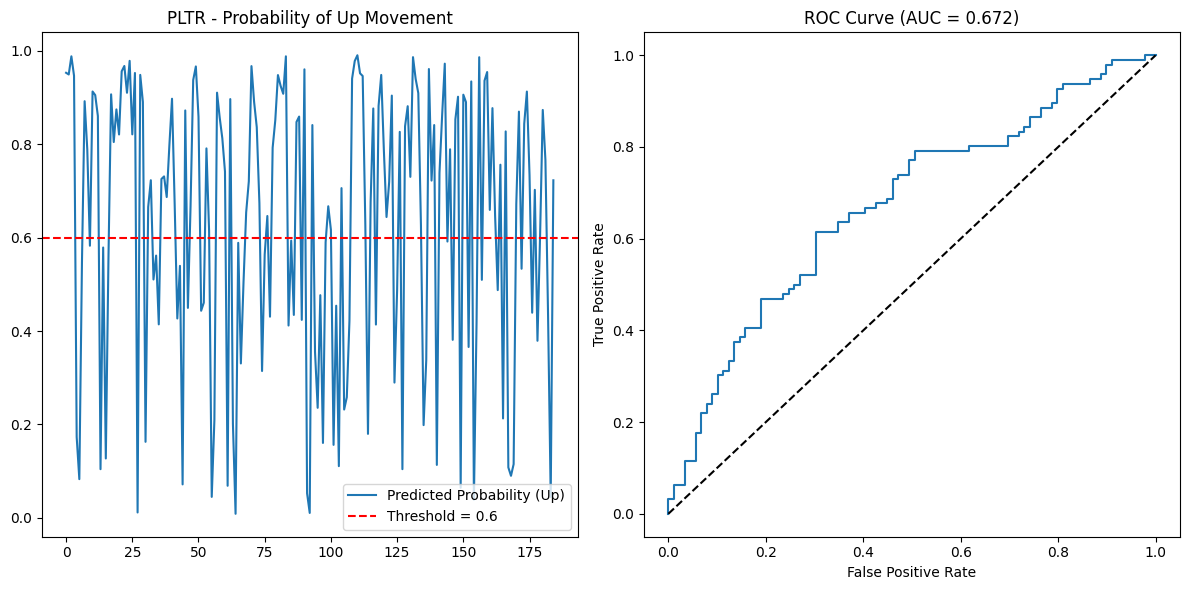

In [8]:
import yfinance as yf
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt

# ----------- Step 1: Load AAPL Data -----------
df = yf.download("PLTR", start="2023-01-01", end="2026-10-31")
df['Return'] = np.log(df['Close'] / df['Close'].shift(1))
df['Momentum'] = df['Close'] - df['Close'].rolling(window=5).mean()
df = df.dropna()

features = df[['Return', 'Momentum']].values
targets = (df['Close'].shift(-1) > df['Close']).astype(int).iloc[:-1]  # Target: price up next day
features = features[:-1]  # Align with target

# ----------- Step 2: Create Sequences -----------
def create_sequences(X, y, seq_len):
    Xs, ys = [], []
    for i in range(len(X) - seq_len):
        Xs.append(X[i:i+seq_len])
        ys.append(y[i+seq_len])
    return np.array(Xs), np.array(ys)

SEQ_LEN = 20
X_seq, y_seq = create_sequences(features, targets.values, SEQ_LEN)

# ----------- Step 3: Dataset / Dataloader -----------
class StockDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)  # Reshape to [batch_size, 1]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, test_size=0.2, shuffle=False)

train_ds = StockDataset(X_train, y_train)
test_ds = StockDataset(X_test, y_test)

train_loader = DataLoader(train_ds, batch_size=32)
test_loader = DataLoader(test_ds, batch_size=32)

# ----------- Step 4: Transformer Classifier -----------
class TransformerBinaryClassifier(nn.Module):
    def __init__(self, input_dim, seq_len, d_model=32, nhead=4, num_layers=2):
        super().__init__()
        self.embedding = nn.Linear(input_dim, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, batch_first=True)  # Set batch_first=True
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Sequential(
            nn.Linear(d_model * seq_len, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.embedding(x)  # (batch, seq_len, d_model)
        x = self.transformer(x)  # No need to permute with batch_first=True
        x = x.reshape(x.size(0), -1)  # flatten
        return self.fc_out(x)  # Already returns shape [batch_size, 1]

# ----------- Step 5: Train the Model -----------
model = TransformerBinaryClassifier(input_dim=2, seq_len=SEQ_LEN)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 20
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        probs = model(X_batch)
        loss = criterion(probs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{num_epochs} | Loss: {total_loss:.4f}")

# ----------- Step 6: Evaluate + Threshold -----------
model.eval()
all_probs, all_labels = [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        probs = model(X_batch)
        all_probs.extend(probs.numpy().flatten())  # Flatten to 1D array
        all_labels.extend(y_batch.numpy().flatten())  # Flatten to 1D array

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

# Try multiple thresholds and find the best one
thresholds = [0.5, 0.6, 0.7, 0.8]
best_f1 = 0
best_threshold = 0.5

for threshold in thresholds:
    preds = (all_probs > threshold).astype(int)
    report = classification_report(all_labels, preds, digits=3, output_dict=True)
    # Check which keys are available in the report
    f1 = report.get('1', {}).get('f1-score',
         report.get('1.0', {}).get('f1-score',
         report.get('weighted avg', {}).get('f1-score', 0.0)))

    print(f"\n--- Evaluation (Threshold = {threshold}) ---")
    print(f"Report keys: {list(report.keys())}")
    print(f"F1 Score: {f1:.3f}")

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

# Final evaluation with best threshold
preds = (all_probs > best_threshold).astype(int)
print(f"\n--- Final Evaluation (Best Threshold = {best_threshold}) ---")
print(classification_report(all_labels, preds, digits=3))
print("AUC Score:", roc_auc_score(all_labels, all_probs))

# ----------- Optional: Plot Predictions -----------
plt.figure(figsize=(12, 6))

# Plot 1: Probability predictions
plt.subplot(1, 2, 1)
plt.plot(all_probs, label="Predicted Probability (Up)")
plt.axhline(best_threshold, color='r', linestyle='--', label=f"Threshold = {best_threshold}")
plt.title("PLTR - Probability of Up Movement")
plt.legend()

# Plot 2: ROC Curve
plt.subplot(1, 2, 2)
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(all_labels, all_probs)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], 'k--')  # Random baseline
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve (AUC = {roc_auc_score(all_labels, all_probs):.3f})')

plt.tight_layout()
plt.show()

In [7]:
print("\n--- ROC CURVE DIAGNOSTICS ---")
print(f"AUC: {roc_auc_score(all_labels, all_probs):.4f}")
print(f"Number of ROC points: {len(fpr)}")
print("\n FPR    TPR    TPR-FPR")

idx = np.linspace(0, len(fpr) - 1, min(15, len(fpr)), dtype=int)

for i in idx:
    print(f"{fpr[i]:.3f}  {tpr[i]:.3f}  {tpr[i]-fpr[i]:+.3f}")

print(f"\nPoints above diagonal: {np.mean(tpr > fpr)*100:.1f}%")
print(f"Points below diagonal: {np.mean(tpr < fpr)*100:.1f}%")



--- ROC CURVE DIAGNOSTICS ---
AUC: 0.5871
Number of ROC points: 83

 FPR    TPR    TPR-FPR
0.000  0.000  +0.000
0.034  0.146  +0.112
0.112  0.240  +0.127
0.157  0.302  +0.145
0.258  0.396  +0.137
0.326  0.469  +0.143
0.360  0.510  +0.151
0.449  0.552  +0.103
0.539  0.615  +0.075
0.629  0.698  +0.069
0.697  0.750  +0.053
0.753  0.823  +0.070
0.831  0.865  +0.033
0.944  0.906  -0.038
1.000  1.000  +0.000

Points above diagonal: 92.8%
Points below diagonal: 4.8%
